In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
df = pd.read_csv('C:\\Users\\thiru\\Downloads\\Project_Telco\\Telco-Customer-Churn.csv',header=0)
df.head()
df.info()
df.describe()
df['Churn'].value_counts(normalize=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [2]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges']

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [3]:
df = df.drop('customerID', axis=1)
df = df.drop_duplicates()
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [4]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['Churn']

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7021, dtype: int64

In [5]:
df['Churn'].unique()
df['Churn'].value_counts(normalize=True)

Churn
0    0.735508
1    0.264492
Name: proportion, dtype: float64

In [6]:
churnbycontract = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)
churnbycontract


Contract
Month-to-month    0.426421
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

In [7]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 60, 72], labels=['0-12', '12-24', '24-48', '48-60', '60-72'])
churnbytenuregroup = df.groupby('tenure_group')['Churn'].mean()
print(churnbytenuregroup)

tenure_group
0-12     0.476080
12-24    0.287109
24-48    0.203890
48-60    0.144231
60-72    0.066098
Name: Churn, dtype: float64


C:\Users\thiru\AppData\Local\Temp\ipykernel_9168\1842578226.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churnbytenuregroup = df.groupby('tenure_group')['Churn'].mean()


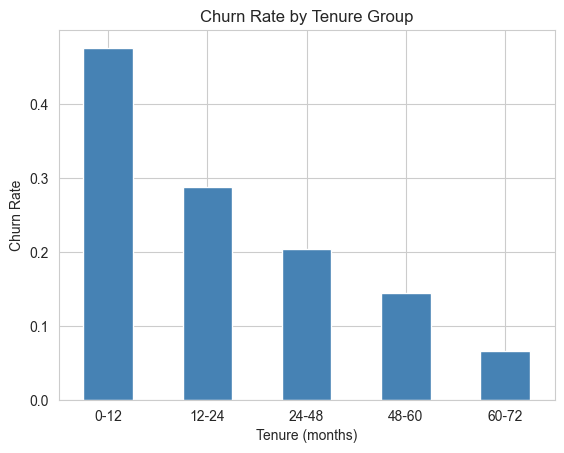

In [8]:
churnbytenuregroup.plot(kind='bar', title='Churn Rate by Tenure Group', color='steelblue')
plt.ylabel('Churn Rate')
plt.xlabel('Tenure (months)')
plt.xticks(rotation=0)
plt.show()

In [9]:
churn_by_InternetService = df.groupby('InternetService')['Churn'].mean().sort_values(ascending = False)
churn_by_InternetService

InternetService
Fiber optic    0.417799
DSL            0.188921
No             0.072090
Name: Churn, dtype: float64

In [10]:
churn_by_OnlineSecurity = df.groupby('OnlineSecurity')['Churn'].mean().sort_values(ascending=False)
churn_by_OnlineSecurity

OnlineSecurity
No                     0.416332
Yes                    0.146112
No internet service    0.072090
Name: Churn, dtype: float64

In [11]:
churn_by_TechSupport = df.groupby('TechSupport')['Churn'].mean().sort_values(ascending = False)
churn_by_TechSupport

TechSupport
No                     0.415007
Yes                    0.151663
No internet service    0.072090
Name: Churn, dtype: float64

In [12]:
churn_by_PaymentMethod = df.groupby('PaymentMethod')['Churn'].mean().sort_values(ascending = False)
churn_by_PaymentMethod

PaymentMethod
Electronic check             0.451462
Mailed check                 0.189223
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: Churn, dtype: float64

<Axes: xlabel='InternetService', ylabel='MonthlyCharges'>

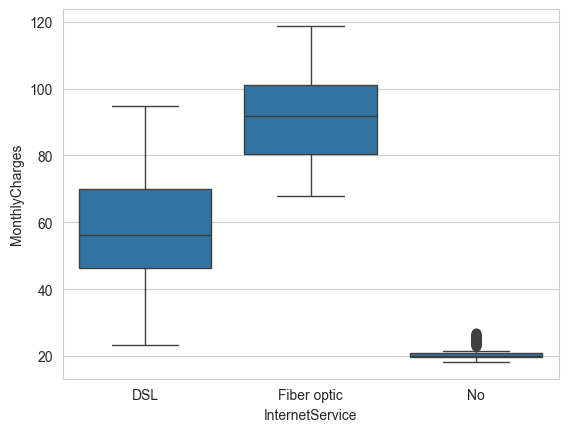

In [13]:
sns.boxplot(x = 'InternetService', y = 'MonthlyCharges', data = df)

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

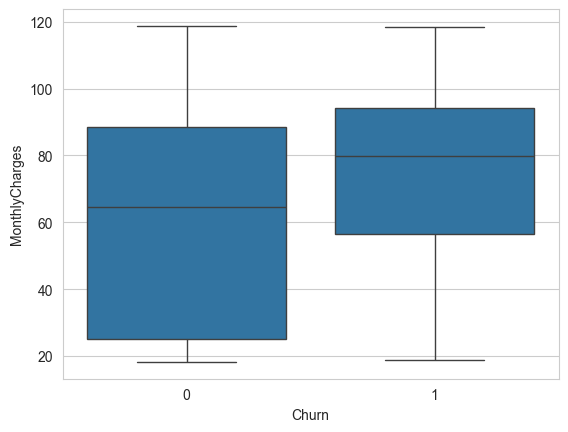

In [14]:
sns.boxplot(x = 'Churn', y = 'MonthlyCharges', data = df)

In [15]:
df = df.drop('tenure_group', axis =1)
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


In [16]:
X = df.drop('Churn', axis = 1)


In [17]:
y = df['Churn']

In [18]:
X = pd.get_dummies(X, drop_first = True)
X = X.astype(int)
X

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29,29,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56,1889,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53,108,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42,1840,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70,151,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84,1990,1,1,1,1,0,1,...,0,1,0,1,1,0,1,0,0,1
7039,0,72,103,7362,0,1,1,1,0,1,...,0,1,0,1,1,0,1,1,0,0
7040,0,11,29,346,0,1,1,0,1,0,...,0,0,0,0,0,0,1,0,1,0
7041,1,4,74,306,1,1,0,1,0,1,...,0,0,0,0,0,0,1,0,0,1


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify=y, random_state = 42)

In [20]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Churn
0    0.735577
1    0.264423
Name: proportion, dtype: float64
Churn
0    0.735231
1    0.264769
Name: proportion, dtype: float64


In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
log_reg = LogisticRegression(random_state = 42)
log_reg.fit(X_train_scaled, y_train)
y_pred = log_reg.predict(X_test_scaled)

In [23]:
print("Accuracy Score : ", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n:", confusion_matrix(y_test, y_pred))
print("\nclassification reports:\n:", classification_report(y_test, y_pred))

Accuracy Score :  0.802846975088968

Confusion matrix:
: [[933 100]
 [177 195]]

classification reports:
:               precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.66      0.52      0.58       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.73      1405
weighted avg       0.79      0.80      0.80      1405



In [24]:
rf = RandomForestClassifier(n_estimators = 100, random_state = 42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [25]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Accuracy: 0.7800711743772242

Confusion Matrix:
 [[933 100]
 [209 163]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.90      0.86      1033
           1       0.62      0.44      0.51       372

    accuracy                           0.78      1405
   macro avg       0.72      0.67      0.69      1405
weighted avg       0.76      0.78      0.77      1405



In [26]:
log_reg_bal = LogisticRegression(class_weight='balanced', random_state=42)
log_reg_bal.fit(X_train_scaled, y_train)

y_pred_bal = log_reg_bal.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_bal))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_bal))
print("\nClassification Report:\n", classification_report(y_test, y_pred_bal))

Accuracy: 0.7409252669039146

Confusion Matrix:
 [[750 283]
 [ 81 291]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.73      0.80      1033
           1       0.51      0.78      0.62       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.75      1405



In [27]:
import numpy as np
import pandas as pd

coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': log_reg_bal.coef_[0]
})
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])
coef_df = coef_df.sort_values('coefficient', ascending=False)

print(coef_df.head(10))   # strongest push toward CHURN
print(coef_df.tail(10))   # strongest push toward STAYING

                           feature  coefficient  odds_ratio
10     InternetService_Fiber optic     0.667291    1.948950
3                     TotalCharges     0.620232    1.859359
23             StreamingMovies_Yes     0.208841    1.232249
21                 StreamingTV_Yes     0.191861    1.211502
9                MultipleLines_Yes     0.172667    1.188470
28  PaymentMethod_Electronic check     0.155320    1.168031
26            PaperlessBilling_Yes     0.153500    1.165908
0                    SeniorCitizen     0.090282    1.094483
8   MultipleLines_No phone service     0.032360    1.032889
17            DeviceProtection_Yes     0.029610    1.030053
                                 feature  coefficient  odds_ratio
18       TechSupport_No internet service    -0.077148    0.925753
12    OnlineSecurity_No internet service    -0.077148    0.925753
16  DeviceProtection_No internet service    -0.077148    0.925753
19                       TechSupport_Yes    -0.079277    0.923784
6         

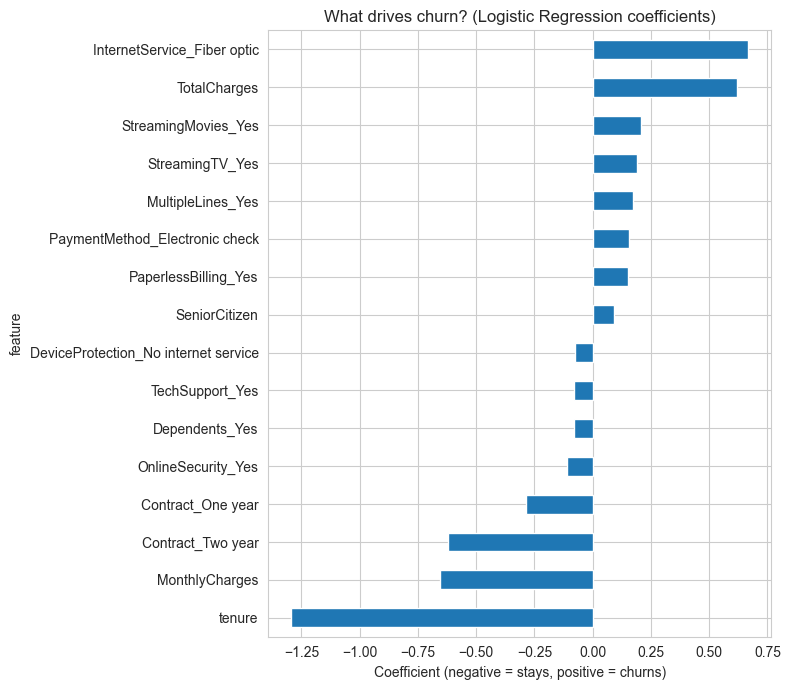

In [28]:
top = pd.concat([coef_df.head(8), coef_df.tail(8)])
top.set_index('feature')['coefficient'].sort_values().plot(
    kind='barh', figsize=(8, 7), title='What drives churn? (Logistic Regression coefficients)'
)
plt.xlabel('Coefficient (negative = stays, positive = churns)')
plt.tight_layout()
plt.show()